# 06 · Graph Attention Network (ST-GAT)

**Objective.** Train the primary research model: a spatio-temporal **graph attention network** that forecasts speed at all 207 sensors for
the next 12 steps, using the validated road graph. Then answer the research question's graph-specific part with an **ablation**: the
*same* network, same parameter count, same training recipe, but with every graph edge removed.

**Why a graph attention network?** Congestion propagates along roads. A graph attention layer lets each sensor re-weight the
information coming from its connected sensors, instead of treating them equally or ignoring them.

**Methodology.**
1. Build the tensors `x [B, 12, 207, 6]` (scaled speed with 0 where missing, observed-mask, 4 calendar features) and the residual-forecast target.
2. Architecture (below), with a numerical check that our masked dense attention equals PyTorch Geometric's `GATConv`.
3. Train with masked MAE, validation-based checkpointing and early stopping; keep only the best-validation weights.
4. Predict validation and test at horizons 1, 3, 6, 12 in **mph** and save for notebook 07. (Test metrics are *not* examined here; the test period stays untouched until the final evaluation.)
5. Train the no-edge ablation under identical conditions.
6. Inspect the learned attention, cautiously.

## Architecture and information flow

```
x [B, T=12, N=207, F=6]
   │ Linear(F→d)                              per sensor and time step
   ▼
[B, T, N, d] ─ GRU over T (weights shared by all sensors) ─▶ h [B, N, d]      temporal encoder
   │ concat learned sensor embedding (16) → Linear → h0 [B, N, d]
   ▼
 2 × GAT block:  z = LayerNorm(g)
                 out = GAT_in(z) + GAT_out(z)      4 heads each, attention only over graph neighbours (+ self)
                 g   = g + Dropout(ELU(out))        residual connection
   ▼
[g, h0] ─ MLP ─▶ residual [B, N, 12]                forecasting head (12 future steps at once)
prediction = anchor + residual                      anchor = last observed speed in the window (same as persistence)
```

* **`GAT_in`**: node *i* attends to sensors *j* with an edge `j → i` (upstream neighbours) and to itself; **`GAT_out`**: to sensors with an edge `i → j` (downstream) and itself. Scores for every other pair are set to `-inf` before the softmax, so they receive *exactly zero* attention. The graph therefore genuinely restricts the attention: nothing is unrestricted all-to-all.
* **Missing data.** Missing inputs are 0 in scaled space (the training mean) *and* flagged by the mask channel. The loss and the validation score count **only observed targets**.
* **Same target as every other model**: speed in mph at steps 1, 3, 6, 12; the network predicts all 12 steps (multi-step training) and we read off those four.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : .../traffic-flow-control  (absolute paths are not printed)
run mode     : full


In [2]:
import json, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from src import data_loader as dl, graph_utils as gu, preprocessing as pp, gat_model as gm, evaluation as ev, visualization as viz
from src.metrics import compute_metrics

viz.apply_style()
dl.require_raw_files()
ctx = pp.load_context()                                          # processed data from notebook 02
graph = gu.load_graph_artifacts(expected_sensor_ids=ctx.sensor_ids)   # raises if the sensor order ever differs
N = len(ctx.sensor_ids)
device = gm.select_device()
print(f"{N} sensors | device: {device} | train/val/test origins: {[len(ctx.origins[k]) for k in pp.SPLIT_NAMES]}")

207 sensors | device: mps | train/val/test origins: [23881, 3445, 6901]


## 1 · Experiment switches and input tensors

`RETRAIN = False` reloads existing checkpoints from `artifacts/models/` instead of training again (useful after a restart); a model whose checkpoint does not exist is trained.
`EXTRA_SEEDS` trains additional seeds of both models, to measure how much results depend on initialisation.

> **Provenance of the delivered run.** The primary models (seed 42: ST-GAT and its no-edge ablation) were trained in an earlier execution of this notebook with `RETRAIN = True`;
> their full epoch-by-epoch training logs are printed again below when the checkpoints are reloaded (the logs are also kept in `artifacts/metrics/*_train.log`). Any model that has no checkpoint yet (for example
> extra seeds listed in `EXTRA_SEEDS`) is trained by the execution whose outputs you see. Set `RETRAIN = True` to reproduce everything from scratch (about 45 minutes per model on an Apple M3).

In [3]:
RETRAIN = False         # True: retrain every model from scratch; False: reuse a checkpoint if it exists (trains it otherwise)
RUN_ABLATION = True     # train the "no edges" twin of the model
EXTRA_SEEDS = (1, 2)    # additional seeds of both models to measure initialisation sensitivity; () = single seed only

params = dict(config.GAT_PARAMS)
data = gm.GraphData(
    speed=ctx.speed, mask=ctx.mask, values_scaled=pp.fill_for_model(ctx.speed, ctx.mask, ctx.scaler),
    time_feats=pp.time_feature_matrix(ctx.timestamps), locf_value=ctx.locf_value, locf_age=ctx.locf_age, scaler=ctx.scaler,
)
train_origins = pp.evenly_spaced(ctx.origins["train"], params["train_origin_limit"])
val_origins, test_origins = ctx.origins["val"], ctx.origins["test"]

x, anchor, y, valid = data.batch(train_origins[:4], torch.device("cpu"))
print("one batch of 4 training origins:")
print(f"  x      {tuple(x.shape)}  [batch, 12 steps, 207 sensors, 6 features]")
print(f"  anchor {tuple(anchor.shape)}  scaled last-observed speed per sensor")
print(f"  y      {tuple(y.shape)}  scaled targets for 12 steps;  valid {tuple(valid.shape)}  (1 = observed target)")
print(f"  share of valid targets in this batch: {valid.mean():.1%} | NaNs in x/y/anchor: {int(torch.isnan(x).sum() + torch.isnan(y).sum() + torch.isnan(anchor).sum())}")
assert not torch.isnan(x).any() and not torch.isnan(y).any() and not torch.isnan(anchor).any()
print("hyper-parameters:", {k: v for k, v in params.items()})

one batch of 4 training origins:
  x      (4, 12, 207, 6)  [batch, 12 steps, 207 sensors, 6 features]
  anchor (4, 207)  scaled last-observed speed per sensor
  y      (4, 12, 207)  scaled targets for 12 steps;  valid (4, 12, 207)  (1 = observed target)
  share of valid targets in this batch: 99.0% | NaNs in x/y/anchor: 0
hyper-parameters: {'d_model': 64, 'n_heads': 4, 'n_gat_layers': 2, 'node_emb_dim': 16, 'dropout': 0.1, 'attn_dropout': 0.1, 'batch_size': 64, 'lr': 0.002, 'weight_decay': 1e-05, 'max_epochs': 30, 'patience': 6, 'grad_clip': 5.0, 'train_origin_limit': None, 'eval_origin_limit': None, 'seed': 42}


## 2 · Build the model and verify that the attention really follows the graph

In [4]:
gm.set_seed(params["seed"])
model = gm.build_model(graph.adjacency, params, use_graph=True)
print(model)
n_params = gm.count_parameters(model)
by_module = pd.Series({n: sum(p.numel() for p in m.parameters()) for n, m in model.named_children()}, name="parameters")
display(by_module.to_frame().assign(share=lambda d: (d["parameters"] / n_params).round(3)))
print(f"total trainable parameters: {n_params:,}")

STGAT(
  (input_proj): Linear(in_features=6, out_features=64, bias=True)
  (gru): GRU(64, 64, batch_first=True)
  (node_emb): Embedding(207, 16)
  (fuse): Linear(in_features=80, out_features=64, bias=True)
  (blocks): ModuleList(
    (0-1): 2 x GATBlock(
      (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (layers): ModuleList(
        (0-1): 2 x DenseGATLayer(
          (lin): Linear(in_features=64, out_features=64, bias=False)
          (attn_dropout): Dropout(p=0.1, inplace=False)
        )
      )
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (head): Sequential(
    (0): Linear(in_features=128, out_features=128, bias=True)
    (1): GELU(approximate='none')
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=128, out_features=12, bias=True)
  )
)


,parameters,share
input_proj,448,0.006
gru,24960,0.360
node_emb,3312,0.048
fuse,5184,0.075
blocks,17408,0.251
head,18060,0.260


total trainable parameters: 69,372


In [5]:
# (a) shapes through the network
model.eval()
with torch.no_grad():
    pred, attentions = model(x, anchor, return_attention=True)
print("prediction", tuple(pred.shape), "= [batch, 12 future steps, 207 sensors] (scaled)")
print("attention per block/direction:", [tuple(a.shape) for a in attentions[0]], "= [batch, target i, source j, heads]")

# (b) attention is exactly zero off the graph and sums to one over the allowed neighbours
masks = gu.neighbor_masks(graph.adjacency)
for b_idx, (att_in, att_out) in enumerate(attentions):
    for name, att in (("in", att_in), ("out", att_out)):
        off_graph = torch.from_numpy(~masks[name])
        assert att[:, off_graph].abs().max().item() == 0.0, "attention leaks outside the graph!"
        assert torch.allclose(att.sum(2), torch.ones_like(att.sum(2)), atol=1e-5)
print("attention is exactly 0 for every non-neighbour pair and normalised over neighbours (both directions, both blocks)")
n_allowed = {k: int(masks[k].sum()) for k in ("in", "out")}
print(f"allowed (i, j) pairs: in {n_allowed['in']} / out {n_allowed['out']} out of {N * N} ({n_allowed['in'] / N ** 2:.1%}) -> not all-to-all")

# (c) equivalence with PyTorch Geometric's GATConv on the same weights (skipped if PyG is not installed)
try:
    from torch_geometric.nn import GATConv
    layer = model.blocks[0].layers[0]
    tgt, src = torch.nonzero(torch.from_numpy(masks["in"]), as_tuple=True)
    conv = GATConv(layer.lin.in_features, layer.out_per_head, heads=layer.heads, add_self_loops=False, dropout=0.0).eval()
    with torch.no_grad():
        conv.lin.weight.copy_(layer.lin.weight); conv.att_src.copy_(layer.att_src); conv.att_dst.copy_(layer.att_dst); conv.bias.copy_(layer.bias)
        z = torch.randn(1, N, layer.lin.in_features)
        diff = (layer.eval()(z, torch.from_numpy(masks["in"]))[0] - conv(z[0], torch.stack([src, tgt]))).abs().max().item()
    print(f"max |dense masked GAT - PyG GATConv| = {diff:.2e}")
    assert diff < 1e-4
except ImportError:
    print("PyTorch Geometric not installed: equivalence check skipped (it is also covered in tests/test_gat_model.py)")

prediction (4, 12, 207) = [batch, 12 future steps, 207 sensors] (scaled)
attention per block/direction: [(4, 207, 207, 4), (4, 207, 207, 4)] = [batch, target i, source j, heads]
attention is exactly 0 for every non-neighbour pair and normalised over neighbours (both directions, both blocks)
allowed (i, j) pairs: in 1722 / out 1722 out of 42849 (4.0%) -> not all-to-all


max |dense masked GAT - PyG GATConv| = 2.38e-07


**Interpretation.** Each node attends to roughly 4% of all node pairs (its in-neighbours or out-neighbours plus itself) and gets
*exactly* zero attention on everything else; the layer reproduces `GATConv` to numerical precision. We implemented the layer
as masked dense attention rather than with sparse scatter operations because N = 207 is small, it batches over time and
samples trivially, and it runs unchanged on CPU, CUDA and Apple MPS.

## 3 · Training

* Loss: **masked MAE** on the scaled targets (every observed target of all 12 steps counts equally; missing targets have zero weight).
* Optimiser: AdamW, learning-rate halving on plateau, gradient clipping.
* **Early stopping and checkpoint selection use the validation MAE in mph.** The best-validation weights are saved to
  `artifacts/models/` and restored at the end.
* The test period is never used here.

In [6]:
def paths(key):
    return (config.MODELS_DIR / f"{config.tagged(key)}.pt", config.METRICS_DIR / f"{config.tagged(key)}_history.json")

def fit_or_load(key, use_graph, seed):
    """Train a model (or reload its checkpoint) and return (model, history)."""
    ckpt, hist_path = paths(key)
    p = dict(params, seed=seed)
    gm.set_seed(seed)
    net = gm.build_model(graph.adjacency, p, use_graph=use_graph)
    if not RETRAIN and ckpt.is_file() and hist_path.is_file():
        gm.load_checkpoint(ckpt, net.to(device), device)
        print(f"[{key}] reloaded checkpoint {ckpt.name}; training log of the run that produced it:")
        log_file = config.METRICS_DIR / f"{config.tagged(key)}_train.log"
        print(log_file.read_text() if log_file.is_file() else "(log file not found)")
        return net, json.loads(hist_path.read_text())
    t0 = time.time()
    log_path = config.METRICS_DIR / f"{config.tagged(key)}_train.log"      # also tail-able while a long run is going
    with open(log_path, "w") as log_file:
        def log(msg):
            print(msg); log_file.write(msg + "\n"); log_file.flush()
        history = gm.train_model(net, data, train_origins, val_origins, device, p, checkpoint_path=ckpt, log=log)
    history["train_seconds"] = time.time() - t0
    history["params"] = {k: str(v) for k, v in p.items()}; history["n_parameters"] = gm.count_parameters(net)
    history["use_graph"] = use_graph; history["seed"] = seed; history["run_mode"] = config.RUN_MODE
    hist_path.write_text(json.dumps(history, indent=2))
    return net, history

t0 = time.time()
gat, gat_hist = fit_or_load("gat", use_graph=True, seed=params["seed"])
print(f"\nST-GAT: best epoch {gat_hist['best_epoch']} | best validation MAE {gat_hist['best_val_mae_mph']:.3f} mph | "
      f"{gat_hist.get('train_seconds', float('nan')) / 60:.1f} min")

[gat] reloaded checkpoint gat.pt; training log of the run that produced it:
epoch   1 | train MAE(scaled) 0.2800 | val MAE 3.1913 mph | lr 2.0e-03 | 88s  *
epoch   2 | train MAE(scaled) 0.2538 | val MAE 3.0381 mph | lr 2.0e-03 | 87s  *
epoch   3 | train MAE(scaled) 0.2455 | val MAE 2.9705 mph | lr 2.0e-03 | 89s  *
epoch   4 | train MAE(scaled) 0.2404 | val MAE 2.9143 mph | lr 2.0e-03 | 114s  *
epoch   5 | train MAE(scaled) 0.2377 | val MAE 2.9500 mph | lr 2.0e-03 | 120s
epoch   6 | train MAE(scaled) 0.2355 | val MAE 2.8867 mph | lr 2.0e-03 | 117s  *
epoch   7 | train MAE(scaled) 0.2341 | val MAE 2.8815 mph | lr 2.0e-03 | 115s  *
epoch   8 | train MAE(scaled) 0.2326 | val MAE 2.8869 mph | lr 2.0e-03 | 114s
epoch   9 | train MAE(scaled) 0.2316 | val MAE 2.8808 mph | lr 2.0e-03 | 522s  *
epoch  10 | train MAE(scaled) 0.2307 | val MAE 2.8606 mph | lr 2.0e-03 | 180s  *
epoch  11 | train MAE(scaled) 0.2299 | val MAE 2.8654 mph | lr 2.0e-03 | 107s
epoch  12 | train MAE(scaled) 0.2294 | val MA

## 4 · Learning curves

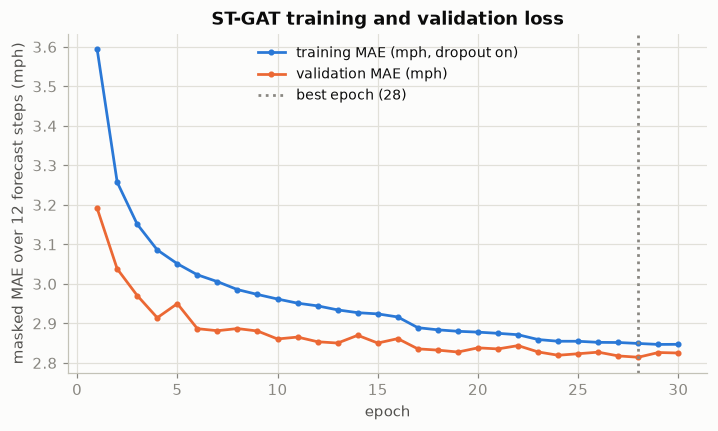

In [7]:
def plot_history(ax, hist, title):
    ep = hist["epoch"]
    ax.plot(ep, np.array(hist["train_loss_scaled"]) * ctx.scaler.std, color="#2a78d6", marker="o", ms=3, label="training MAE (mph, dropout on)")
    ax.plot(ep, hist["val_mae_mph"], color="#eb6834", marker="o", ms=3, label="validation MAE (mph)")
    ax.axvline(hist["best_epoch"], color=viz.INK_MUTED, ls=":", label=f"best epoch ({hist['best_epoch']})")
    ax.set_xlabel("epoch"); ax.set_ylabel("masked MAE over 12 forecast steps (mph)"); ax.set_title(title); ax.legend()

fig, ax = plt.subplots(figsize=(7.5, 4))
plot_history(ax, gat_hist, "ST-GAT training and validation loss")
viz.save_figure(fig, "06_gat_learning_curves"); plt.show()

**Interpretation.** The training and validation curves should decrease together; the dotted line marks the epoch whose weights are
kept. The training MAE is measured with dropout active and averaged over each epoch while the weights change, so it is expected to sit
slightly above or below the validation curve; the two are not strictly comparable.

## 5 · Forecasts at horizons 1, 3, 6, 12 (in mph)

Predictions are produced in scaled units and **inverse-transformed** with the training scaler before they are saved or scored.
Only validation metrics are shown here.

In [8]:
def forecast_and_save(model, key):
    out = {}
    for split, origins in (("val", val_origins), ("test", test_origins)):
        pred = gm.predict_mph(model, data, origins, device, steps=config.HORIZONS)
        assert pred.shape == (len(origins), len(config.HORIZONS), N) and np.isfinite(pred).all()
        # inverse transform check: re-derive from the scaled forecast of the same model
        z = gm.predict_scaled(model, data, origins[:16], device)[:, [h - 1 for h in config.HORIZONS], :]
        assert np.allclose(pred[:16], z * ctx.scaler.std + ctx.scaler.mean, atol=1e-3)
        ev.save_predictions(key, split, pred, origins, config.HORIZONS,
                            {"model": key, "run_mode": config.RUN_MODE, "units": "mph", "target": "speed at origin + h steps"})
        out[split] = pred
    return out

gat_pred = forecast_and_save(gat, "gat")
print({k: v.shape for k, v in gat_pred.items()}, "= [samples, horizons, sensors] in mph")

yv, mv = pp.gather_targets(ctx.speed, ctx.mask, val_origins, config.HORIZONS)
rows = [{"horizon_min": h * 5, **compute_metrics(gat_pred["val"][:, j], yv[:, j], mv[:, j])} for j, h in enumerate(config.HORIZONS)]
print("validation metrics of the ST-GAT:")
display(pd.DataFrame(rows).set_index("horizon_min").round(3))

{'val': (3445, 4, 207), 'test': (6901, 4, 207)} = [samples, horizons, sensors] in mph
validation metrics of the ST-GAT:


,MAE,RMSE,MAPE,n_valid,n_valid_mape
horizon_min,,,,,
5,2.116,3.691,4.960,665707,665705
15,2.513,4.851,6.481,665293,665291
30,2.849,5.796,7.884,664672,664670
60,3.243,6.812,9.502,663840,663838


## 6 · Ablation: the same network without graph edges

`use_graph=False` keeps every layer and the parameter count identical but lets each sensor attend only to **itself**, so the
attention layers collapse to per-sensor linear maps. Any difference from the ST-GAT is therefore attributable to the road
graph, not to model size, capacity or training recipe.

[gat_nograph] reloaded checkpoint gat_nograph.pt; training log of the run that produced it:
epoch   1 | train MAE(scaled) 0.2857 | val MAE 3.3040 mph | lr 2.0e-03 | 104s  *
epoch   2 | train MAE(scaled) 0.2601 | val MAE 3.1341 mph | lr 2.0e-03 | 128s  *
epoch   3 | train MAE(scaled) 0.2508 | val MAE 3.0724 mph | lr 2.0e-03 | 159s  *
epoch   4 | train MAE(scaled) 0.2461 | val MAE 3.0338 mph | lr 2.0e-03 | 168s  *
epoch   5 | train MAE(scaled) 0.2430 | val MAE 3.0479 mph | lr 2.0e-03 | 235s
epoch   6 | train MAE(scaled) 0.2414 | val MAE 3.0095 mph | lr 2.0e-03 | 222s  *
epoch   7 | train MAE(scaled) 0.2398 | val MAE 3.0064 mph | lr 2.0e-03 | 202s  *
epoch   8 | train MAE(scaled) 0.2386 | val MAE 2.9968 mph | lr 2.0e-03 | 216s  *
epoch   9 | train MAE(scaled) 0.2377 | val MAE 3.0044 mph | lr 2.0e-03 | 226s
epoch  10 | train MAE(scaled) 0.2371 | val MAE 3.0009 mph | lr 2.0e-03 | 182s
epoch  11 | train MAE(scaled) 0.2364 | val MAE 2.9880 mph | lr 2.0e-03 | 223s  *
epoch  12 | train MAE(scal

,parameters,best epoch,best validation MAE (mph)
model,,,
ST-GAT (graph),69372,28,2.814
ST-GAT without edges,69372,28,2.952


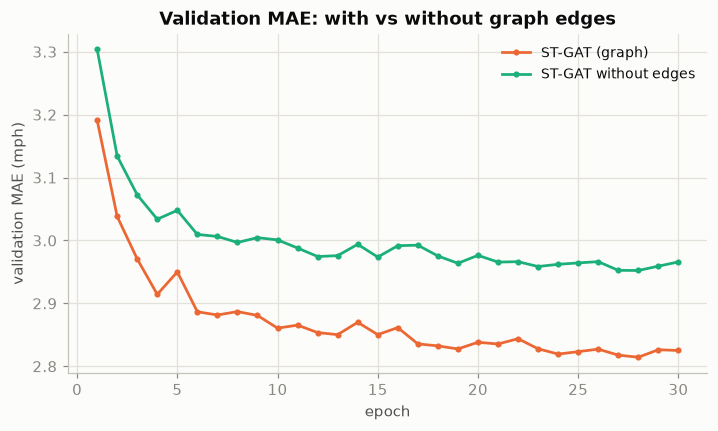

In [9]:
assert gm.count_parameters(gm.build_model(graph.adjacency, params, use_graph=False)) == gm.count_parameters(gat)
if RUN_ABLATION:
    nograph, nograph_hist = fit_or_load("gat_nograph", use_graph=False, seed=params["seed"])
    nograph_pred = forecast_and_save(nograph, "gat_nograph")
    rows = []
    for name, hist in (("ST-GAT (graph)", gat_hist), ("ST-GAT without edges", nograph_hist)):
        rows.append({"model": name, "parameters": hist.get("n_parameters", gm.count_parameters(gat)), "best epoch": hist["best_epoch"],
                     "best validation MAE (mph)": round(hist["best_val_mae_mph"], 3)})
    display(pd.DataFrame(rows).set_index("model"))
    fig, ax = plt.subplots(figsize=(7.5, 4))
    for hist, key, label in ((gat_hist, "gat", "ST-GAT (graph)"), (nograph_hist, "gat_nograph", "ST-GAT without edges")):
        ax.plot(hist["epoch"], hist["val_mae_mph"], color=viz.style(key)["color"], marker="o", ms=3, label=label)
    ax.set_xlabel("epoch"); ax.set_ylabel("validation MAE (mph)"); ax.set_title("Validation MAE: with vs without graph edges"); ax.legend()
    viz.save_figure(fig, "06_gat_vs_nograph_validation"); plt.show()
else:
    print("ablation skipped (RUN_ABLATION = False)")

In [10]:
if RUN_ABLATION:
    g, n_ = np.array(gat_hist["val_mae_mph"]), np.array(nograph_hist["val_mae_mph"])
    k = min(len(g), len(n_))
    gap = 100 * (nograph_hist["best_val_mae_mph"] - gat_hist["best_val_mae_mph"]) / nograph_hist["best_val_mae_mph"]
    below = int((g[:k] < n_[:k]).sum())
    print(f"best validation MAE: with edges {gat_hist['best_val_mae_mph']:.3f} mph, without edges {nograph_hist['best_val_mae_mph']:.3f} mph -> the graph variant is {gap:.1f}% lower")
    print(f"the graph variant has the lower validation MAE in {below} of the {k} epochs both were trained")
    display(ev.report_claims({"the graph variant has the lower best-validation MAE": gap > 0, "it is lower in at least 90% of the epochs": below >= int(0.9 * k)}))

best validation MAE: with edges 2.814 mph, without edges 2.952 mph -> the graph variant is 4.7% lower
the graph variant has the lower validation MAE in 30 of the 30 epochs both were trained


,claim,holds in this run
0,the graph variant has the lower best-validatio...,True
1,it is lower in at least 90% of the epochs,True


**Interpretation (validation period, one training run each).** The two networks are identical except that the second one's attention is restricted to each sensor itself. The version that may use
its road-graph neighbours reaches a lower validation error and stays below the no-edge version through (almost) the whole training, so the gap is not an artefact of picking one epoch. This is
validation evidence from a single seed; the test-period comparison with confidence intervals is in notebook 07.

## 7 · Optional: more seeds

Neural-network results depend on initialisation. If `EXTRA_SEEDS` is non-empty, both models are retrained for each extra seed and saved as
`gat_seed<k>` / `gat_nograph_seed<k>`; notebook 07 reports the spread when those files exist.

In [11]:
for seed in EXTRA_SEEDS:
    for key, use_graph in (("gat", True), ("gat_nograph", False)):
        if key == "gat_nograph" and not RUN_ABLATION:
            continue
        net, hist = fit_or_load(f"{key}_seed{seed}", use_graph, seed)
        forecast_and_save(net, f"{key}_seed{seed}")
        print(f"{key} seed {seed}: best validation MAE {hist['best_val_mae_mph']:.3f} mph")
if not EXTRA_SEEDS:
    print("no extra seeds requested (set EXTRA_SEEDS = (1, 2) to run them)")

[gat_seed1] reloaded checkpoint gat_seed1.pt; training log of the run that produced it:
epoch   1 | train MAE(scaled) 0.2786 | val MAE 3.1868 mph | lr 2.0e-03 | 90s  *
epoch   2 | train MAE(scaled) 0.2551 | val MAE 3.0251 mph | lr 2.0e-03 | 2900s  *
epoch   3 | train MAE(scaled) 0.2463 | val MAE 2.9893 mph | lr 2.0e-03 | 92s  *
epoch   4 | train MAE(scaled) 0.2415 | val MAE 2.9441 mph | lr 2.0e-03 | 91s  *
epoch   5 | train MAE(scaled) 0.2384 | val MAE 2.9273 mph | lr 2.0e-03 | 95s  *
epoch   6 | train MAE(scaled) 0.2362 | val MAE 2.9223 mph | lr 2.0e-03 | 91s  *
epoch   7 | train MAE(scaled) 0.2348 | val MAE 2.9121 mph | lr 2.0e-03 | 85s  *
epoch   8 | train MAE(scaled) 0.2333 | val MAE 2.8737 mph | lr 2.0e-03 | 86s  *
epoch   9 | train MAE(scaled) 0.2321 | val MAE 2.8903 mph | lr 2.0e-03 | 85s
epoch  10 | train MAE(scaled) 0.2312 | val MAE 2.8894 mph | lr 2.0e-03 | 85s
epoch  11 | train MAE(scaled) 0.2304 | val MAE 2.8617 mph | lr 2.0e-03 | 86s  *
epoch  12 | train MAE(scaled) 0.2295

gat seed 1: best validation MAE 2.820 mph
[gat_nograph_seed1] reloaded checkpoint gat_nograph_seed1.pt; training log of the run that produced it:
epoch   1 | train MAE(scaled) 0.2829 | val MAE 3.2864 mph | lr 2.0e-03 | 93s  *
epoch   2 | train MAE(scaled) 0.2603 | val MAE 3.1342 mph | lr 2.0e-03 | 97s  *
epoch   3 | train MAE(scaled) 0.2524 | val MAE 3.1000 mph | lr 2.0e-03 | 91s  *
epoch   4 | train MAE(scaled) 0.2475 | val MAE 3.0463 mph | lr 2.0e-03 | 90s  *
epoch   5 | train MAE(scaled) 0.2443 | val MAE 3.0507 mph | lr 2.0e-03 | 402s
epoch   6 | train MAE(scaled) 0.2423 | val MAE 3.0269 mph | lr 2.0e-03 | 9449s  *
epoch   7 | train MAE(scaled) 0.2411 | val MAE 2.9874 mph | lr 2.0e-03 | 97s  *
epoch   8 | train MAE(scaled) 0.2395 | val MAE 3.0082 mph | lr 2.0e-03 | 99s
epoch   9 | train MAE(scaled) 0.2382 | val MAE 3.0026 mph | lr 2.0e-03 | 103s
epoch  10 | train MAE(scaled) 0.2377 | val MAE 2.9897 mph | lr 1.0e-03 | 87s
epoch  11 | train MAE(scaled) 0.2355 | val MAE 2.9656 mph | lr

gat_nograph seed 1: best validation MAE 2.943 mph
[gat_seed2] reloaded checkpoint gat_seed2.pt; training log of the run that produced it:
epoch   1 | train MAE(scaled) 0.2784 | val MAE 3.2124 mph | lr 2.0e-03 | 94s  *
epoch   2 | train MAE(scaled) 0.2532 | val MAE 3.0365 mph | lr 2.0e-03 | 93s  *
epoch   3 | train MAE(scaled) 0.2448 | val MAE 2.9767 mph | lr 2.0e-03 | 97s  *
epoch   4 | train MAE(scaled) 0.2402 | val MAE 2.9368 mph | lr 2.0e-03 | 92s  *
epoch   5 | train MAE(scaled) 0.2375 | val MAE 2.9361 mph | lr 2.0e-03 | 91s  *
epoch   6 | train MAE(scaled) 0.2356 | val MAE 2.9099 mph | lr 2.0e-03 | 92s  *
epoch   7 | train MAE(scaled) 0.2338 | val MAE 2.8949 mph | lr 2.0e-03 | 91s  *
epoch   8 | train MAE(scaled) 0.2328 | val MAE 2.8865 mph | lr 2.0e-03 | 92s  *
epoch   9 | train MAE(scaled) 0.2315 | val MAE 2.8774 mph | lr 2.0e-03 | 94s  *
epoch  10 | train MAE(scaled) 0.2308 | val MAE 2.8710 mph | lr 2.0e-03 | 93s  *
epoch  11 | train MAE(scaled) 0.2299 | val MAE 2.8885 mph | lr

gat seed 2: best validation MAE 2.807 mph
[gat_nograph_seed2] reloaded checkpoint gat_nograph_seed2.pt; training log of the run that produced it:
epoch   1 | train MAE(scaled) 0.2843 | val MAE 3.3239 mph | lr 2.0e-03 | 96s  *
epoch   2 | train MAE(scaled) 0.2605 | val MAE 3.1473 mph | lr 2.0e-03 | 91s  *
epoch   3 | train MAE(scaled) 0.2516 | val MAE 3.1031 mph | lr 2.0e-03 | 97s  *
epoch   4 | train MAE(scaled) 0.2458 | val MAE 3.0443 mph | lr 2.0e-03 | 93s  *
epoch   5 | train MAE(scaled) 0.2431 | val MAE 3.0335 mph | lr 2.0e-03 | 93s  *
epoch   6 | train MAE(scaled) 0.2412 | val MAE 3.0295 mph | lr 2.0e-03 | 112s  *
epoch   7 | train MAE(scaled) 0.2397 | val MAE 3.0388 mph | lr 2.0e-03 | 127s
epoch   8 | train MAE(scaled) 0.2387 | val MAE 3.0053 mph | lr 2.0e-03 | 115s  *
epoch   9 | train MAE(scaled) 0.2375 | val MAE 3.0014 mph | lr 2.0e-03 | 117s  *
epoch  10 | train MAE(scaled) 0.2370 | val MAE 2.9925 mph | lr 2.0e-03 | 117s  *
epoch  11 | train MAE(scaled) 0.2362 | val MAE 2.999

gat_nograph seed 2: best validation MAE 2.957 mph


## 8 · What does the graph model attend to? (cautious inspection)

We average the attention weights of the first block over a sample of **validation** origins and compare them with the uniform
weights a model with no preference would use (1 / number of neighbours). **Attention weights show how the trained network mixes neighbour
representations; they are not causal evidence that one sensor "causes" congestion at another.**

In [12]:
masks_np = gu.neighbor_masks(graph.adjacency)
sample_origins = pp.evenly_spaced(val_origins, 256)
att_sum = {"in": 0.0, "out": 0.0}; n_seen = 0
gat.eval()
with torch.no_grad():
    for i in range(0, len(sample_origins), 64):
        xb, ab, _, _ = data.batch(sample_origins[i:i + 64], device)
        _, atts = gat(xb, ab, return_attention=True)
        att_sum["in"] = att_sum["in"] + atts[0][0].float().mean(-1).sum(0).cpu().numpy()     # head-averaged, [N, N] (target i, source j)
        att_sum["out"] = att_sum["out"] + atts[0][1].float().mean(-1).sum(0).cpu().numpy()
        n_seen += xb.shape[0]
mean_att = {k: v / n_seen for k, v in att_sum.items()}

rows = []
for name in ("in", "out"):
    m, a = masks_np[name], mean_att[name]
    n_nb = m.sum(1)
    self_att = np.diag(a)
    rows.append({"direction": name, "mean attention on itself": self_att.mean(), "uniform value (1 / neighbourhood size)": (1 / n_nb).mean(),
                 "share of nodes with self-attention above uniform": float((self_att > 1 / n_nb).mean()),
                 "mean neighbourhood size (incl. self)": n_nb.mean()})
display(pd.DataFrame(rows).set_index("direction").round(3))

# How selective is the attention? normalised entropy per sensor: 1 = uniform over its neighbourhood, 0 = all weight on one neighbour
sel_rows = []
for name in ("in", "out"):
    m, a = masks_np[name], mean_att[name]
    ent, ratio = [], []
    for i in range(N):
        nb_idx = np.flatnonzero(m[i])
        if len(nb_idx) < 3:
            continue
        w = a[i, nb_idx] / a[i, nb_idx].sum()
        ent.append(float(-(w * np.log(w + 1e-12)).sum() / np.log(len(nb_idx)))); ratio.append(float(w.max() * len(nb_idx)))
    sel_rows.append({"direction": name, "sensors with >= 3 neighbours": len(ent), "mean normalised entropy (1 = uniform)": np.mean(ent),
                     "share of sensors with entropy < 0.9": float(np.mean(np.array(ent) < 0.9)), "mean (largest weight / uniform weight)": np.mean(ratio)})
selectivity = pd.DataFrame(sel_rows).set_index("direction")
display(selectivity.round(3))
ent_mean = selectivity["mean normalised entropy (1 = uniform)"]
display(ev.report_claims({
    "mean normalised attention entropy is between 0.85 and 1 (mildly selective) in both directions": bool(((ent_mean > 0.85) & (ent_mean < 1.0)).all()),
    "the largest attention weight is on average > 1.2x the uniform weight": bool((selectivity["mean (largest weight / uniform weight)"] > 1.2).all()),
    "a few sensors are strongly selective (entropy < 0.9)": bool((selectivity["share of sensors with entropy < 0.9"] > 0).all()),
}))

,mean attention on itself,uniform value (1 / neighbourhood size),share of nodes with self-attention above uniform,mean neighbourhood size (incl. self)
direction,,,,
in,0.175,0.169,0.449,8.319
out,0.175,0.175,0.483,8.319


,sensors with >= 3 neighbours,mean normalised entropy (1 = uniform),share of sensors with entropy < 0.9,mean (largest weight / uniform weight)
direction,,,,
in,191,0.960,0.016,1.803
out,193,0.974,0.010,1.652


,claim,holds in this run
0,mean normalised attention entropy is between 0...,True
1,the largest attention weight is on average > 1...,True
2,a few sensors are strongly selective (entropy ...,True


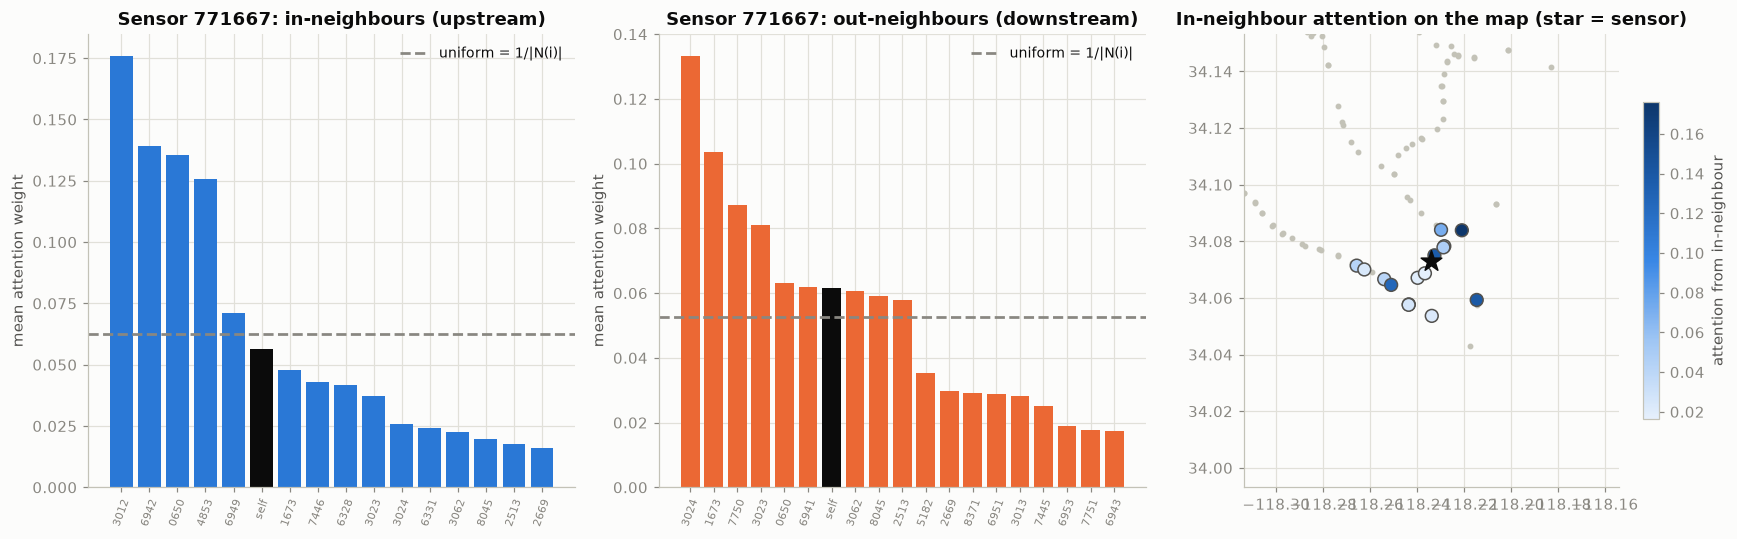

In [13]:
# Attention of one well-connected sensor, averaged over the validation sample
deg = (masks_np["in"].sum(1) + masks_np["out"].sum(1))
hub = int(np.argmax(deg))
loc = graph.locations
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, name, ttl in ((axes[0], "in", "in-neighbours (upstream)"), (axes[1], "out", "out-neighbours (downstream)")):
    w = mean_att[name][hub]; nb_idx = np.flatnonzero(masks_np[name][hub])
    order = nb_idx[np.argsort(-w[nb_idx])]
    ax.bar(range(len(order)), w[order], color=["#0b0b0b" if j == hub else ("#2a78d6" if name == "in" else "#eb6834") for j in order])
    ax.axhline(1 / len(nb_idx), color=viz.INK_MUTED, ls="--", label="uniform = 1/|N(i)|")
    ax.set_xticks(range(len(order)), [("self" if j == hub else graph.sensor_ids[j][-4:]) for j in order], rotation=70, fontsize=7)
    ax.set_ylabel("mean attention weight"); ax.set_title(f"Sensor {graph.sensor_ids[hub]}: {ttl}"); ax.legend()
lon, lat = loc["longitude"].to_numpy(), loc["latitude"].to_numpy()
axes[2].scatter(lon, lat, s=8, color="#c3c2b7")
w_in = mean_att["in"][hub]; nbs = [j for j in np.flatnonzero(masks_np["in"][hub]) if j != hub]
sc = axes[2].scatter(lon[nbs], lat[nbs], c=w_in[nbs], cmap=viz.SPEED_CMAP.reversed(), s=70, edgecolor=viz.INK_2, zorder=3)
axes[2].scatter(lon[hub], lat[hub], marker="*", s=200, color=viz.INK, zorder=4)
axes[2].set_xlim(lon[hub] - 0.08, lon[hub] + 0.08); axes[2].set_ylim(lat[hub] - 0.08, lat[hub] + 0.08)
axes[2].set_aspect(1 / np.cos(np.deg2rad(lat.mean()))); plt.colorbar(sc, ax=axes[2], shrink=0.7, label="attention from in-neighbour")
axes[2].set_title("In-neighbour attention on the map (star = sensor)")
fig.tight_layout(); viz.save_figure(fig, "06_gat_attention_hub"); plt.show()

**Interpretation (cautious).**

* *On average the attention is only mildly selective.* The attention a sensor pays to itself is close to the uniform value (first table), and the normalised entropy over each sensor's neighbours is close to 1 (second table; 1 = perfectly uniform; checked in code):
  the largest weight is on average only about 1.5-2x the uniform weight, and only a small share of sensors is strongly selective.
* *A few sensors are strongly selective.* The hub shown above (the most connected sensor, chosen for its connectivity, **not** because it is typical) concentrates weight on a handful of neighbours and clearly differs from the uniform line.
* So the gain of the graph model over the no-edge ablation should **not** be explained as "sharply picking the right neighbour" for most sensors; it may come largely from mixing neighbour information with only modest re-weighting. That explanation is a hypothesis we did not test.
* These weights are averages over many time steps of a learned, non-causal mixing step (the graph block sits on top of a recurrent encoder and a residual path); we do not read them as influence, flow or causation between roads.
* Whether the graph helps forecasting is answered by the ablation and by the test-set comparison in notebook 07, not by this plot.

## 9 · Summary of this notebook

In [14]:
rows = [{"model": "ST-GAT (graph)", "parameters": f"{gm.count_parameters(gat):,}", "best epoch": gat_hist["best_epoch"],
         "best val MAE (mph)": round(gat_hist["best_val_mae_mph"], 3), "checkpoint": paths("gat")[0].name}]
if RUN_ABLATION:
    rows.append({"model": "ST-GAT without edges", "parameters": f"{gm.count_parameters(nograph):,}", "best epoch": nograph_hist["best_epoch"],
                 "best val MAE (mph)": round(nograph_hist["best_val_mae_mph"], 3), "checkpoint": paths("gat_nograph")[0].name})
display(pd.DataFrame(rows).set_index("model"))
saved = sorted({p.name for p in config.PREDICTIONS_DIR.glob(f"{config.tagged('gat')}*__*.npz")})
print("prediction files:", saved)
if config.IS_SMOKE:
    print("\n*** SMOKE RUN: these numbers come from a tiny debug configuration and are NOT experimental results. ***")
print("\nNext: 07_model_evaluation.ipynb (after notebooks 04 and 05 have produced the baseline / XGBoost predictions)")

,parameters,best epoch,best val MAE (mph),checkpoint
model,,,,
ST-GAT (graph),"69,372",28,2.814,gat.pt
ST-GAT without edges,"69,372",28,2.952,gat_nograph.pt


prediction files: ['gat__test.npz', 'gat__val.npz', 'gat_nograph__test.npz', 'gat_nograph__val.npz', 'gat_nograph_seed1__test.npz', 'gat_nograph_seed1__val.npz', 'gat_nograph_seed2__test.npz', 'gat_nograph_seed2__val.npz', 'gat_seed1__test.npz', 'gat_seed1__val.npz', 'gat_seed2__test.npz', 'gat_seed2__val.npz']

Next: 07_model_evaluation.ipynb (after notebooks 04 and 05 have produced the baseline / XGBoost predictions)
